### Top Rows

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

file_path = "results-filtered.csv"
df = pd.read_csv(file_path)

numeric_cols=["v0-heur", "v0-ctcp", "v1-heur", "v1-ctcp", "v4-heur", "v4-ctcp", "v0-S-bnb", "v0-S-total", "v0-R-bnb", "v0-R-total", "v0-P-bnb", "v0-P-total", "v1-S-bnb", "v1-S-total", "v1-R-bnb", "v1-R-total", "v1-P-bnb", "v1-P-total", "v4-S-bnb", "v4-S-total", "v4-R-bnb", "v4-R-total", "v4-P-bnb", "v4-P-total"]

valid_cols = [c for c in numeric_cols if c in df.columns]
df[valid_cols] = (
    df[valid_cols]
    .replace("x", 1800)
    .apply(pd.to_numeric, errors="coerce")
)




=== A wins (speedup >= 2) ===
      v0-ctcp  v1-ctcp  speedup_a
144       0.3      4.0       13.3
145       0.3      4.4       16.3
146       0.3      3.9       13.2
147       0.3      4.2       15.7
148       0.3      4.4       15.2
...       ...      ...        ...
4351      1.0     35.6       36.8
4352      1.0     32.3       32.3
4353      1.2     31.2       25.9
4354      1.0     29.4       28.3
4355      1.2     24.6       20.2

[1154 rows x 3 columns]

=== B wins (speedup >= 2) ===
      v0-ctcp  v1-ctcp  speedup_b
1261      1.5      0.7        2.0
1262      1.4      0.6        2.3
1263      1.5      0.5        3.0
3044      1.0      0.4        2.4
3056      1.2      0.6        2.0
3057      1.2      0.6        2.2
3058      1.1      0.6        2.1
3061      1.2      0.6        2.2
3062      1.2      0.6        2.1
3063      1.2      0.6        2.2
3067      1.3      0.6        2.0
3068      1.3      0.6        2.1
3069      1.2      0.6        2.0
3136      1.2      0.2       

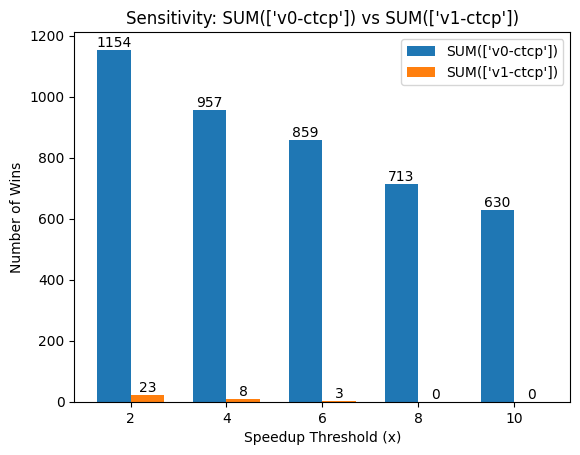

In [100]:
# =========================
# CONFIG
# =========================
cols_a = ["v0-ctcp"]
cols_b = ["v1-ctcp"]

thresholds = [2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.001)

# =========================
# Compute sums
# =========================
df["sum_a"] = df[cols_a].sum(axis=1)
df["sum_b"] = df[cols_b].sum(axis=1)

# =========================
# Filter small runtimes
# =========================
df_filtered = df[(df["sum_a"] >= min_time_threshold) | (df["sum_b"] >= min_time_threshold)].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered["sum_b"] / df_filtered["sum_a"]
df_filtered["speedup_b"] = df_filtered["sum_a"] / df_filtered["sum_b"]

# =========================
# PRINT winning cases for threshold = 2
# =========================
threshold_check = 2

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check]
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check]

print(f"\n=== A wins (speedup >= {threshold_check}) ===")
print(a_wins[[*cols_a, *cols_b, "speedup_a"]])

print(f"\n=== B wins (speedup >= {threshold_check}) ===")
print(b_wins[[*cols_a, *cols_b, "speedup_b"]])

# =========================
# Evaluate across thresholds
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot (grouped bar chart)
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=f"SUM({cols_a})")
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=f"SUM({cols_b})")

# =========================
# Annotate bars
# =========================
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

# =========================
# Labels & title
# =========================
plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of Wins")
plt.title(f"Sensitivity: SUM({cols_a}) vs SUM({cols_b})")

plt.legend()

plt.show()

### Varying Ratio Threshold


=== Threshold 2 Analysis ===
v0-ctcp wins: 407
v4-ctcp wins: 116

Weaker side: col_a
Sorted in descending order of speedup:



,dataset,k,v0-ctcp,v4-ctcp,speedup_a,v0-heur,v4-heur,v0-prep,v4-prep,v0-S-total,v4-S-total,v0-R-total,v4-R-total,v0-P-total,v4-P-total
4176,web-wikipedi...,8,318.2,1800.0,5.7,85.2,1800.0,False,False,256.7,1800.0,245.1,1800.0,280.0,1800.0
4221,wikipedia-li...,8,253.1,1800.0,7.1,72.8,1800.0,False,False,272.4,1800.0,246.6,1800.0,280.9,1800.0
1847,karted,8,0.0,1800.0,1800000000000000.0,0.1,1800.0,False,False,65.3,1800.0,63.7,1800.0,65.7,1800.0
1966,livejournal-...,20,681.1,1800.0,2.6,48.7,1800.0,False,False,1133.8,1800.0,1156.4,1800.0,1126.2,1800.0
3488,soc-livejour...,20,631.5,1800.0,2.9,35.2,1800.0,False,False,1138.3,1800.0,1078.3,1800.0,1144.9,1800.0
1846,karted,7,0.0,1800.0,1800000000000000.0,0.1,1800.0,False,False,64.1,1800.0,65.4,1800.0,64.1,1800.0
313,bag-pubmed,3,162.0,1800.0,11.1,185.2,1800.0,False,False,328.6,1800.0,436.2,1800.0,328.6,1800.0
312,bag-pubmed,2,168.1,1800.0,10.7,240.0,1800.0,False,False,342.6,1800.0,277.5,1800.0,322.8,1800.0
4175,web-wikipedi...,7,299.0,1082.0,3.6,86.5,10.6,False,False,268.8,1091.2,233.0,1061.3,270.9,1071.4
4220,wikipedia-li...,7,269.0,1042.4,3.9,76.4,10.4,False,False,249.0,1071.5,255.1,1069.1,254.7,1119.5


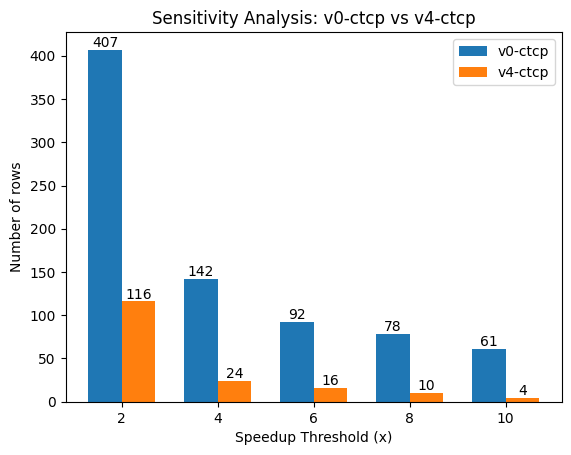

In [104]:
# =========================
# CONFIG
# =========================
col_a = "v0-ctcp"
col_b = "v4-ctcp"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df[f"{va}-prep"] = df[f"{va}-S-bnb"] == "prep"
df[f"{vb}-prep"] = df[f"{vb}-S-bnb"] == "prep"

df_filtered = df[(df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)].copy()
# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = 2

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# Determine weaker side
if len(a_wins) > len(b_wins):
    weaker = "A"
    weaker_df = a_wins.sort_values(by="v4-ctcp", ascending=False)
    speed_col = "speedup_a"
    wc=col_a.split("-")[0]
elif len(b_wins) > len(a_wins):
    weaker = "B"
    weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
    speed_col = "speedup_b"
    wc=col_b.split("-")[0]
else:
    weaker = "Tie"
    weaker_df = None
pd.set_option('display.float_format', '{:.1f}'.format)
# =========================
# Print weaker side
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)



if weaker == "Tie":
    print("Both sides have equal wins.")
else:
    print(f"\nWeaker side: {'col_a' if weaker == 'A' else 'col_b'}")
    print("Sorted in descending order of speedup:\n")
    max_len = 12  # choose what you like

    display(
        weaker_df.assign(
            dataset=weaker_df["dataset"].apply(
                lambda x: x[:max_len] + "..." if len(x) > max_len else x
            )
        )[["dataset", "k", col_a, col_b, speed_col, f"{va}-heur", f"{vb}-heur", f"{va}-prep", f"{vb}-prep", f"{va}-S-total", f"{vb}-S-total", f"{va}-R-total", f"{vb}-R-total",f"{va}-P-total",  f"{vb}-P-total"]]
    )

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

# Annotate
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()